# SEM reflection calibration from diffraction images

**Native Gaussian column → saved detector pixels → measured order shapes → independent fit → geometry and prediction checks.**

Recover **source position and size, the positions and reference focal lengths of C1, C2 and the objective, and the initial detector distance**. The surface is the axial origin. Neither the objective working distance nor the initial camera distance is given to the fitter. The camera moves by known **laboratory-Z translations of −25, 0 and +25 mm**, with its orientation and height fixed.

This follows the TEM microscope calibration pipeline (removed in the 2026-11-06 cleanup; Git revision `b2d873e` retains it): analysis reads saved images and recorded commands; truth is separate; independent starts, uncertainties and unused settings test the fit. The browser pairs saved images with native column diagrams and lets you switch between **Initial guess**, **Fitted model** and optional **Ground truth**.

This first exploration uses a **local Gaussian reflection model**, not the full angular-packet renderer. Three separated Cu(001) orders inherit the existing reflection adapter's envelope Jacobian. This notebook tests parameter recovery within that approximation.

In [1]:
import os
from pathlib import Path
import json
import numpy as np

# The modest moment fit runs comfortably on CPU. Set this before importing JAX.
os.environ.setdefault("JAX_PLATFORMS", "cpu")
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
import jax
jax.config.update("jax_enable_x64", True)
from temgym_core import reflection_calibration as reflection
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

HEADLESS = os.environ.get("TEMGYM_HEADLESS", "0") == "1"
get_ipython().run_line_magic("matplotlib", "inline" if HEADLESS else "widget")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 120})
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/temgym_core").exists())
OUT = ROOT / "examples/sem_reflection/output/calibration_gaussian"
print("JAX:", jax.__version__, jax.devices())
print("Results:", OUT)

JAX: 0.10.2 [CpuDevice(id=0)]
Results: /Users/landers/TemGymCore/examples/sem_reflection/output/calibration_gaussian


## 1. Define the experiment

The ideal column uses native `Lens` components and a diffraction-limited Gaussian source waist. The **mechanical inclination is 2°**, as in the reflection example; here the beam is on axis at **2° incidence**, with no deflector kicks or objective aberrations. This isolates source/lens recovery from unknown steering calibration. Lens sweeps may defocus the beam freely.

The Cu surface period, 30 kV energy, 55 µm detector pitch, detector orientation, surface hit and incidence are treated as independently known. The detector PSF and noise are also calibrated. Its initial centre lies on the known specular ray at unknown distance $L_0$. A subsequent translation is $\mathbf c_D=L_0\hat{\mathbf n}_{out}+\Delta Z\hat{\mathbf Z}$: it does **not** follow the specular ray vertically.

The recorded commands are **relative lens powers**, with $1/f_i(u_i)=u_i/f_{i,0}$. These are a declared synthetic control law, not measured hardware currents. The fitter estimates the three unknown reference focal lengths. Axial bounds are engineering assumptions, not soft priors; the original 40 mm working distance is only part of the generating instrument.

There are **111 fitting images** (37 lens settings × 3 detector positions) and **18 prediction images** (six independent combined lens settings × 3 positions). The acquisition combines individual ±10/20% lens changes with joint changes. Each image receives $10^9$ incident electrons, independently of numerical pixel quadrature. Unknown incident dose does not enter the geometry fit: total order intensities are not fitted.

In [2]:
specification = reflection.default_specification()
settings = reflection.acquisition()
table = ["| Parameter | Initial guess | Lower bound | Upper bound |",
         "|---|---:|---:|---:|"]
for name, initial, lo, hi in zip(reflection.NAMES, reflection.INITIAL, reflection.LOWER, reflection.UPPER):
    table.append(f"| {name} | {initial:g} | {lo:g} | {hi:g} |")
display(Markdown("\n".join(table)))
print({purpose: int(np.sum(settings["purpose"] == purpose)) for purpose in ("fit", "check")})

| Parameter | Initial guess | Lower bound | Upper bound |
|---|---:|---:|---:|
| Source z (mm) | -390 | -500 | -310 |
| C1 z (mm) | -250 | -300 | -200 |
| C2 z (mm) | -145 | -180 | -85 |
| Objective z (mm) | -52 | -75 | -15 |
| C1 f (mm) | 46 | 20 | 80 |
| C2 f (mm) | 30 | 12 | 55 |
| Objective f (mm) | 25 | 10 | 50 |
| Source RMS (nm) | 2.5 | 0.7 | 5 |
| Initial camera distance (mm) | 145 | 80 | 180 |

{'fit': 111, 'check': 18}


## 2. Make and save detector images

The generator transports the source through the native column and maps its Gaussian envelope into the three outgoing diffraction orders. It integrates correlated Gaussian intensity over actual detector pixels, after the calibrated PSF. Order amplitudes use the same Cu scattering factors and smooth potential-step response as the reflection example, with fixed normalization; detector clipping is not renormalized.

The local approximation holds the surface response and envelope map fixed at the chief ray. Summing order intensities is justified only when their fields have negligible overlap; the final checks report an overlap bound and the fraction outside each order's measurement strip. This is **not** a sum of independent angular-basis packet intensities. Angular-response variation within the beam and nonlinear angular scattering are deferred to a later full-renderer validation.

The generator saves `images.npz`, `settings.npz` and `experiment.json`. Only `scoring_truth.json` contains the generating geometry. A nonempty acquisition folder is never silently overwritten. To change the experiment or noise seed, choose a new `OUT`.

In [3]:
if not (OUT / "images.npz").exists():
    reflection.simulate_experiment(OUT, specification=specification, settings=settings, seed=7)
else:
    print("Using the saved acquisition; fitting will read its recorded specification and commands.")
display(Markdown("```json\n" + (OUT / "generation_checks.json").read_text() + "```"))

```json
{
  "seed": 7,
  "frames": 129,
  "max_pixel_quadrature_error_noise_units": 1.5154664938413583e-10,
  "expected_order_counts": [
    2241547.760118679,
    6432978.129932453,
    2241547.760118679
  ],
  "note": "Checks numerical integration of the reduced Gaussian model, not full angular reflection."
}
```

## 3. Measure the saved pixels

Locate the three resolved orders from the lateral image profile, then measure each order's two centroids and two variances. Their full 4×4 measurement covariance includes the correlation between those statistics under counting and read noise. No true geometry or noiseless image is used in extraction.

The predictor integrates the Gaussian marginals into pixel-centre moments, including narrow spots, PSF and the finite measurement strips. It does not treat the recorded variances as exact continuous beam widths. Negligible order clipping and overlap are requirements checked at the final solution.

In [4]:
reflection.measure_images(OUT)
print("Measured saved pixels; generating geometry was not read.")

Measured saved pixels; generating geometry was not read.


## Inspect the initial guess

The detector panel shows the **saved image**; orange contours show the selected model's predicted 2σ ellipses. The column diagram uses `trace_gaussian_basis` and `plot_reflection_column`, including the same lens symbols and envelope style as the reflection example. The incident envelope is magnified by a fixed factor of 60; axial positions and camera geometry use physical coordinates.

The static comparison is preserved in notebook output. With a live widget backend, the browser below adds record, fit/check and model selectors in the form used by the microscope calibration notebook.

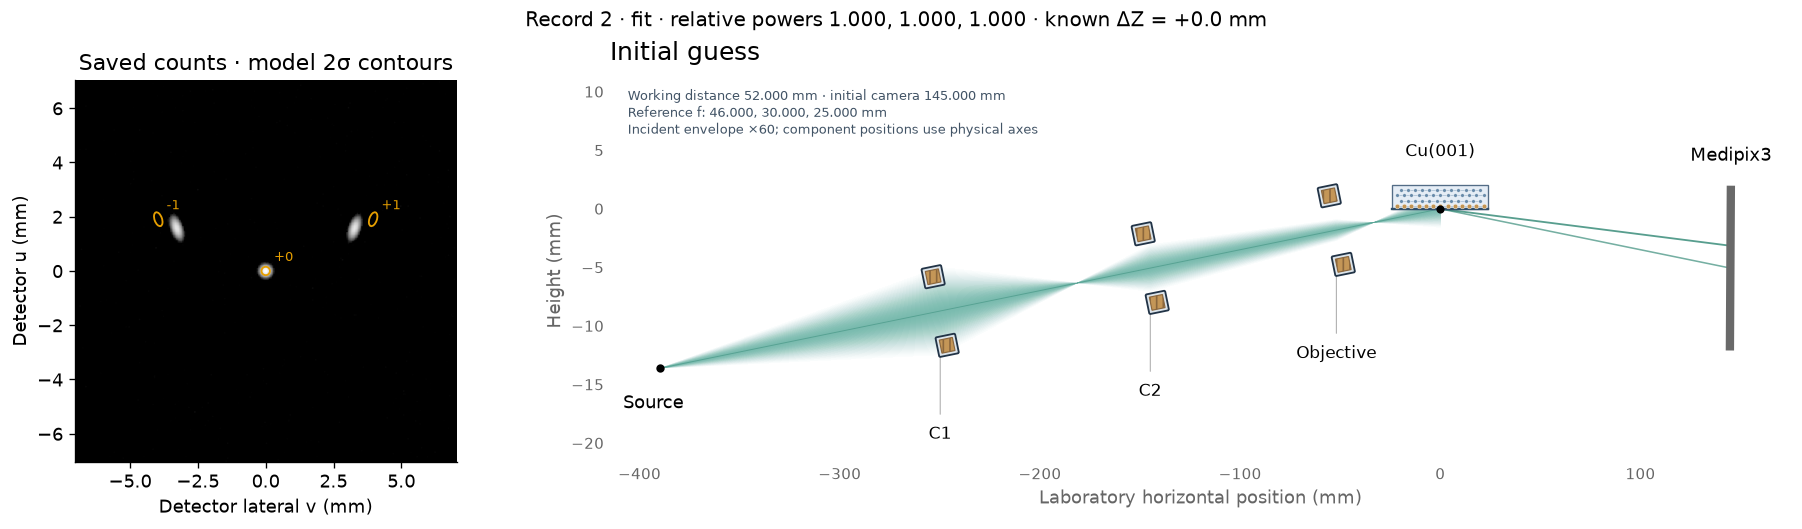

In [5]:
initial_figure = reflection.plot_comparison(OUT, row=1, models=("Initial guess",))
plt.show()
if not HEADLESS:
    display(reflection.browse_images(OUT))

## 4. Fit the microscope independently

Three stages avoid assuming the correct optical branch:

1. Estimate initial camera distance from measured diffraction-order positions and known translations.
2. Explore ten independent bounded starts with a spot-shape initialization objective. These include the displayed initial guess and broad draws across the engineering bounds.
3. Refine the three best initializations against the **original measured moments and full covariance**, using the existing bounded JAX least-squares solver. The initialization data are not counted a second time.

All initialization and refinement outcomes are saved, including wrong branches and iteration-limit failures. The final report checks data consistency, scaled-Jacobian rank and proximity to bounds. Covariance is local, conditioned on the declared model assumptions; it is not evidence of global uniqueness.

**Truth isolation:** temporarily move the optional truth file out of the analysis directory during fitting. The fitter never opens it. The file is restored in `finally` solely for the later browser and geometry score.

In [6]:
truth_file = OUT / "scoring_truth.json"
held_truth = OUT.parent / (OUT.name + "_scoring_truth.held.json")
if held_truth.exists():
    raise RuntimeError("A previous run was interrupted: restore the held scoring file before continuing.")
if truth_file.exists():
    truth_file.rename(held_truth)
try:
    fitted = reflection.fit_microscope(OUT, number_of_starts=10)
finally:
    if held_truth.exists():
        held_truth.rename(truth_file)
print("Data-consistent interior fit:", fitted["accepted"])
print("Local rank:", fitted["rank"], "/", len(reflection.NAMES))

Initialize 1/10: shape cost=44.740; ftol


Initialize 2/10: shape cost=45.115; iteration_limit


Initialize 3/10: shape cost=44.740; ftol


Initialize 4/10: shape cost=44.741; ftol


Initialize 5/10: shape cost=4.509; ftol


Initialize 6/10: shape cost=92.384; ftol


... (4 outputs left out)

Refine 1: chi²=1366.155; ftol


Refine 2: chi²=1366.155; ftol


Refine 3: chi²=1366.155; ftol


Data-consistent interior fit: True
Local rank: 9 / 9


## 5. Check prediction and recovered geometry

The six withheld lens settings were excluded from both initialization and refinement. Compare their noise-normalized prediction residuals with the fitting residuals. The geometry table uses the **same formatter as the microscope calibration notebook**, showing fitted values, optional truth, errors and local standard deviations.

Inspect the source/lens uncertainties and parameter correlations, not just image agreement. A full local rank can coexist with poorly determined geometry. A result near an engineering bound or with incorrect prediction residuals is not accepted simply because the optimizer stopped.

In [7]:
checks = reflection.check_microscope(OUT)
display(reflection.show_result(OUT))
print("Maximum lost lateral fraction:", checks["max_lateral_tail_fraction"])
print("Maximum order field-overlap bound:", checks["max_order_field_overlap_bound"])
print("Recovered objective working distance (mm):", checks["objective_working_distance_mm"])

Local rank 9/9; near bounds: none
Fit accepted: True; prediction/approximation checks: True
Fit RMS: 1.013; prediction RMS: 1.011


| Parameter | Fitted | Truth | Error | Standard deviation |
|---|---:|---:|---:|---:|
| Source z (mm) | -347.802 | -350 | 2.19762 | 9.81568 |
| C1 z (mm) | -269.27 | -270 | 0.729797 | 5.83122 |
| C2 z (mm) | -130.551 | -130 | -0.551491 | 1.56097 |
| Objective z (mm) | -40.154 | -40 | -0.153953 | 0.275092 |
| C1 f (mm) | 39.3897 | 40 | -0.610318 | 1.76027 |
| C2 f (mm) | 25.694 | 25.7143 | -0.0202784 | 0.522232 |
| Objective f (mm) | 21.2792 | 21.1765 | 0.102696 | 0.204696 |
| Source RMS (nm) | 1.8889 | 1.91 | -0.021096 | 0.0509425 |
| Initial camera distance (mm) | 120 | 120 | -0.000119879 | 0.000107784 |

Maximum lost lateral fraction: 1.03509423847073e-16
Maximum order field-overlap bound: 3.8865933955782474e-16
Recovered objective working distance (mm): 40.15395340430102


## Initial guess and final fit

Both rows use the same recorded exposure, contrast and diagram limits. The geometry changes are visible directly; the orange detector contours reveal the corresponding improvement in predicted beam shape. This comparison is exported as PNG, SVG and PDF using `export_ray_figure`.

The second browser includes the fitted model. Switch to a held-out record to inspect a prediction rather than a fitting image.

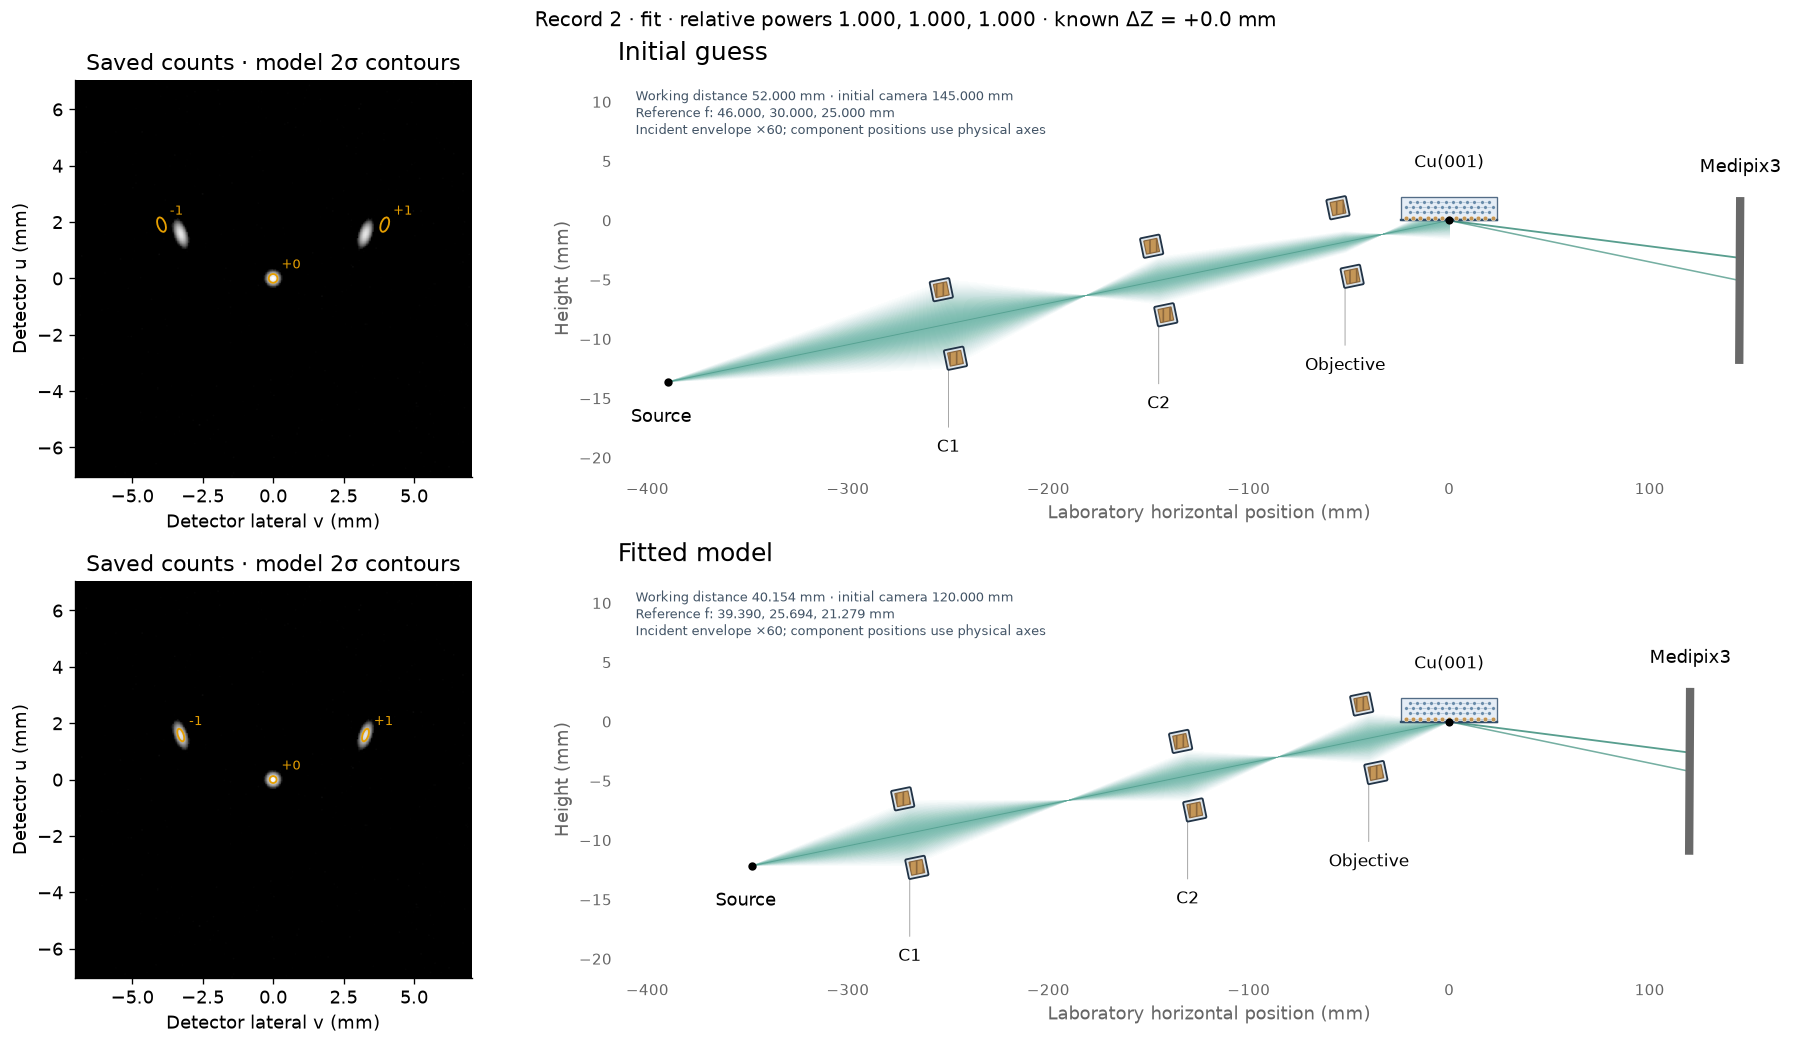

In [8]:
comparison = reflection.plot_comparison(OUT, row=1, export=True)
plt.show()
if not HEADLESS:
    display(reflection.browse_images(OUT))

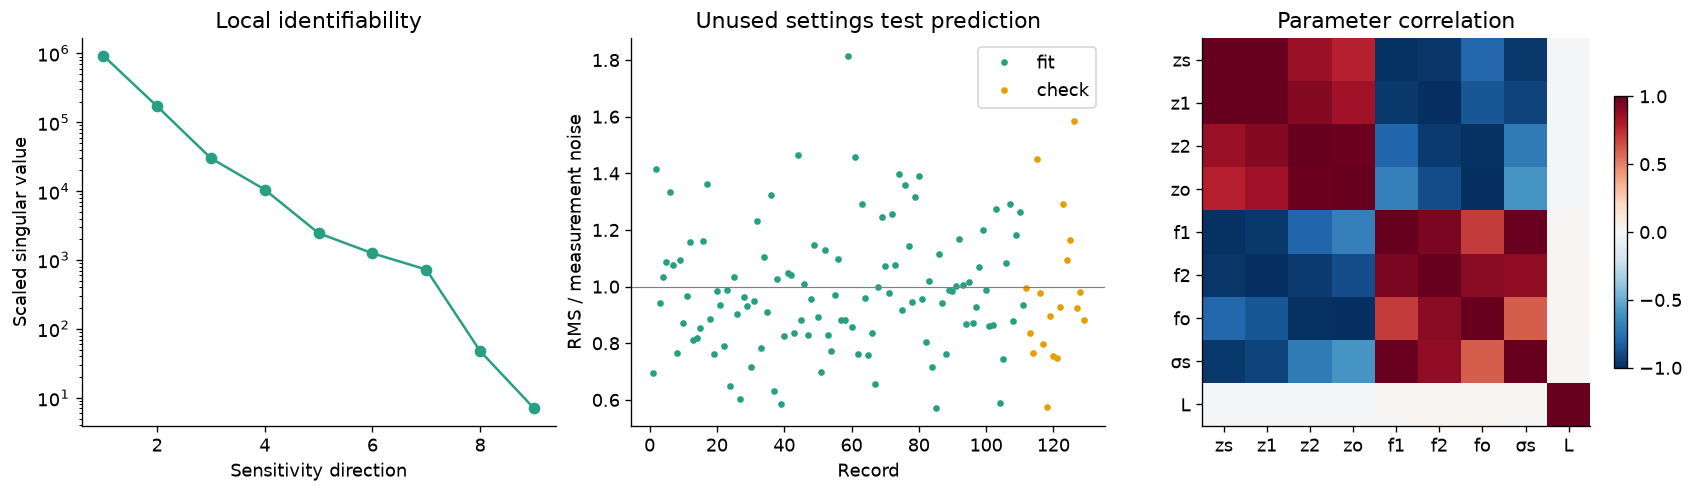

In [9]:
diagnostics = reflection.plot_diagnostics(OUT)
plt.show()
from temgym_core.plotting import export_ray_figure
export_ray_figure(diagnostics, OUT / "fit_diagnostics", dpi=160,
                  metadata={"rank": fitted["rank"], "held_out_frames": checks["held_out_frames"]});

## What this experiment establishes

This is a reproducible test of whether the nine parameters can be recovered **within the local Gaussian reflection model and the stated calibrations**. It does not yet establish that real SEM data or the full angular-packet reflection simulation would give unbiased lens positions. Source coherence, incidence, detector pose, PSF and the relative-power control law are held fixed assumptions.

The source and lens geometry can be strongly correlated even when camera distance is tightly constrained by known lattice spacing. Multiple successful starts support the identified branch within the explored bounds; local rank and covariance do not prove global uniqueness.

The next physical check is to generate images with the existing angular-packet reflection adapter and fit those pixels with this reduced predictor. A mismatch above measurement noise would require improving the reflection prediction before interpreting the fitted positions. Follow that with noise repeats, acquisition-range comparisons, and nuisance parameters for imperfect incidence or detector alignment.